```{contents}
:local:
:depth: 2
```

# 2.6 Non-convex Problems and Bounding

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 5, Lesson 3: *Global Optimization Methods*
- Module 5, Lesson 6: *Bounding Functions*

Lesson 3 comes before the branch-and-bound lessons in the videos; its idea of a relaxation that bounds the original problem was already used for MILPs in Topic 2.5, and here it is extended to non-convex functions.
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Recognize a non-convex problem from its picture, and explain why a local solver's "optimal" is not a guarantee on it.
- Use multistart, and explain why it finds good solutions but proves nothing.
- State what makes a relaxation valid, and build convex underestimators: the secant of a concave term, and McCormick envelopes of a bilinear term.
- Carry out spatial branch-and-bound, which branches on continuous variables to tighten convex relaxations until the bounds meet.
- Solve a non-convex MINLP with one tree that branches on binaries and on intervals, and explain why the bounds must be valid for the answer to be trusted.
:::

Every bound computed by branch-and-bound in Topic 2.5 could be trusted. This was because the relaxation at each node was an LP, and since an LP is convex, the answer returned by the solver is the true minimum of the relaxation. In this topic we will ask what happens when the relaxation is not convex.

Remember that Topic 2.4 ended with the S-shaped power curve, which is an acknowledged exaggeration of the low-load Faraday-efficiency loss of real stacks:

$$
P_i(x) = x + a_i \frac{x}{x + \epsilon} + r_i x^2 ,
$$

with the ideal energy $x$, a concave smoothed fixed charge, and a convex ohmic loss. We will first see the effect of this curve on the simplest dispatch problem. Then we will build relaxations that still give valid bounds, and finally we will solve the full electrolyzer MINLP with a certificate of global optimality.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pyomo.environ as pyo
plt.style.use('../settings/plot_style.mplstyle')
from _lib import electrolyzer as el
from _lib import part2b_tools as bt

a, r = bt.CELLS['A']                     # stack A: parasitic size a = 0.3, ohmic r = 0.5
print(f"eps = {bt.EPS}, F_on = {bt.F_ON}, x_min = {bt.X_MIN}; stacks (a, r): {bt.CELLS}")

eps = 0.05, F_on = 0.12, x_min = 0.1; stacks (a, r): {'A': (0.3, 0.5), 'B': (0.4, 0.35), 'C': (0.2, 0.7)}


## Non-convexity you can see

We will take two identical stacks of type A and a demand of $D = 0.9$ (180 kg/h), with no binaries. In this case there is only one decision, the load $x$ on the first stack, since the second stack carries $0.9 - x$. Along the demand line the ideal-energy terms add up to the constant $D$, which means that the split only trades losses. If we plot the **loss** (i.e. the power above ideal), this constant is removed and the shape becomes visible. Due to symmetry, only half of the range is needed, where $x = 0$ means that one stack runs alone and $x = 0.45$ is the equal split.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


one stack runs:  loss 0.6892, total power 1.58921 = 10.39 MW
equal split:     loss 0.7425, total power 1.64250 = 10.73 MW
barrier:         loss 0.8076 at x = 0.093


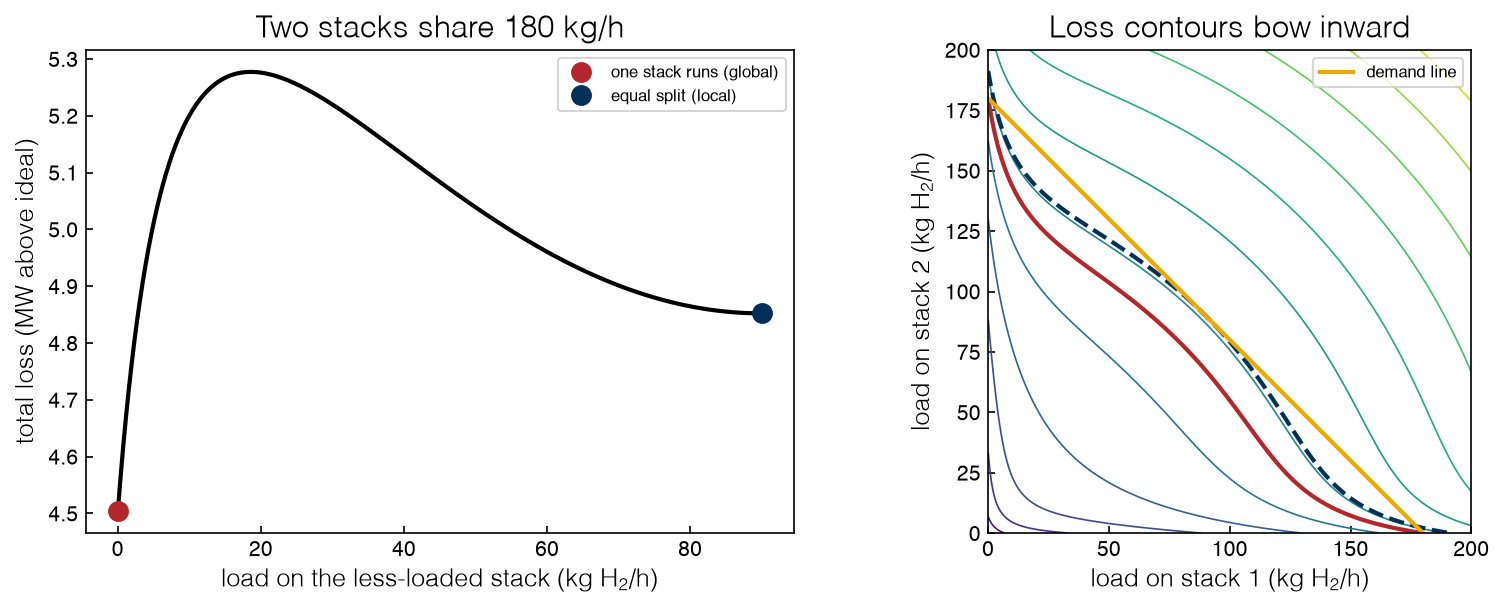

In [2]:
D = 0.9
loss = lambda x: bt.g(x, a) + r * x**2                    # power above ideal, one stack
x = np.linspace(0, D / 2, 3001)
f = loss(x) + loss(D - x)
kmax = int(np.argmax(f))
print(f"one stack runs:  loss {f[0]:.4f}, total power {f[0] + D:.5f} = {el.to_mw(f[0] + D):.2f} MW")
print(f"equal split:     loss {f[-1]:.4f}, total power {f[-1] + D:.5f} = {el.to_mw(f[-1] + D):.2f} MW")
print(f"barrier:         loss {f[kmax]:.4f} at x = {x[kmax]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].plot(el.to_kg_h(x), el.to_mw(f), 'k')
axes[0].plot([0], [el.to_mw(f[0])], 'o', color='#B3262B', ms=9, label='one stack runs (global)')
axes[0].plot([el.to_kg_h(D / 2)], [el.to_mw(f[-1])], 'o', color='#003057', ms=9, label='equal split (local)')
axes[0].set_xlabel('load on the less-loaded stack (kg H$_2$/h)')
axes[0].set_ylabel('total loss (MW above ideal)')
axes[0].set_title('Two stacks share 180 kg/h')
axes[0].legend(fontsize=8)
g1 = np.linspace(0, 1, 301)
X1, X2 = np.meshgrid(g1, g1)
Z = loss(X1) + loss(X2)
axes[1].contour(el.to_kg_h(X1), el.to_kg_h(X2), el.to_mw(Z), levels=14, linewidths=0.8, cmap='viridis')
axes[1].contour(el.to_kg_h(X1), el.to_kg_h(X2), el.to_mw(Z), levels=[el.to_mw(f[0])], colors='#B3262B')
axes[1].contour(el.to_kg_h(X1), el.to_kg_h(X2), el.to_mw(Z), levels=[el.to_mw(f[-1])], colors='#003057', linestyles='--')
axes[1].plot(el.to_kg_h([0, D]), el.to_kg_h([D, 0]), color='#EAAA00', lw=2, label='demand line')
axes[1].set_xlabel('load on stack 1 (kg H$_2$/h)'); axes[1].set_ylabel('load on stack 2 (kg H$_2$/h)')
axes[1].set_title('Loss contours bow inward')
axes[1].set_aspect('equal'); axes[1].legend(fontsize=8, loc='upper right')
plt.tight_layout()

We can see that there are two valleys in the left plot. If only one stack is running, the loss is 0.6892, for a total of 1.58921 per-unit (10.39 MW), while the equal split has a loss of 0.7425, for a total of 1.6425 (10.73 MW). Between these two valleys there is a barrier of 0.8076 at a load of 0.093 on the smaller stack. The global minimum is a boundary point where one stack is off, and the local minimum is an interior point. **The local minima are operating configurations**, \"one stack carries the load\" and \"share it equally\". Most of the smoothed fixed charge of a lightly loaded second stack is paid for very little hydrogen, so the plant is better off with the second stack switched off.

The same thing is shown in the right plot in the language of Topic 2.2, where non-convexity can be recognized from level sets that bow inward. The dashed level of the local minimum is tangent to the demand line at the equal split, which is the Lagrange picture from Topic 2.2. The solid level of the global minimum only touches the demand line at the axes, where the bound $x_i \ge 0$ is active, and this is the complementary-slackness picture of the KKT conditions. Note that both points satisfy the KKT conditions, but only one of them is optimal.

:::{exercise}
:label: ex-t26-wells

Count the local minima of the two-stack split (on the full range $0 \le x \le D$) for demands $D = 0.4, 0.6, 0.8, 1.0, 1.2$, by scanning a fine grid and testing each point against its neighbors. For which demands is equal sharing the global optimum? Explain the result at $D = 1.2$, where one stack alone cannot carry the demand.
:::

## Local solvers stop in the wrong well

A local solver (such as SLSQP or Ipopt) moves downhill from the starting point until the KKT conditions are satisfied. On this problem both valleys satisfy the KKT conditions, so the solver will stop in the valley that contains the starting point. In the next cell we start SLSQP three times by hand and then from twenty random points. The second experiment is the simplest defense, **multistart**, where we run the local solver from many starting points and keep the best answer.

In [3]:
def total(v):
    return bt.P(v[0], a, r) + bt.P(v[1], a, r)

demand = [{'type': 'eq', 'fun': lambda v: v[0] + v[1] - D}]
for start in [(0.45, 0.45), (0.7, 0.2), (0.05, 0.85)]:
    res = minimize(total, start, method='SLSQP', bounds=[(0, 1)] * 2, constraints=demand)
    print(f"start {start} -> x = {np.round(res.x, 4)}, power {res.fun:.5f}, success = {res.success}")

rng = np.random.default_rng(0)
starts = rng.uniform(0, D, 20)
results = []
for s in starts:
    res = minimize(total, [s, D - s], method='SLSQP', bounds=[(0, 1)] * 2, constraints=demand)
    results.append(res.fun)
results = np.array(results)
n_global = int(np.sum(results < 1.58921 + 1e-4))
print(f"{n_global} of {len(starts)} random starts reach the global optimum; best found {results.min():.5f}")

start (0.45, 0.45) -> x = [0.45 0.45], power 1.64250, success = True
start (0.7, 0.2) -> x = [0.45 0.45], power 1.64250, success = True
start (0.05, 0.85) -> x = [0.  0.9], power 1.58921, success = True
8 of 20 random starts reach the global optimum; best found 1.58921


If we start from the equal split, or even from the lopsided start $(0.7, 0.2)$, SLSQP returns the equal split at 1.6425 and reports success. Only the start at $(0.05, 0.85)$, which is already near the boundary, finds the global optimum of 1.58921, which is 3.4% better. There is nothing in the first two outputs to indicate the existence of a better answer.

Here eight of the twenty random starts reach the global optimum, so multistart has no trouble finding it in this case, but multistart does not provide any proof of optimality. With more variables the number of valleys will multiply and the basin of the best valley may be tiny, so no number of starts can certify that no valley was missed. To *prove* that a point is globally optimal we need a lower bound that holds everywhere, and the rest of this topic is about building this lower bound. (In {doc}`../3-data_driven_optimization/Topic3.3-Global_Sampling_and_Evolutionary_Methods` we will see another route to such a certificate: methods such as DIRECT, which bound a function from its values alone by using a known limit on the rate of change of the function.)

:::{exercise}
:label: ex-t26-multistart

Repeat the multistart experiment with 5, 20 and 100 starts and ten different seeds each. Estimate the probability that a single random start finds the global optimum, and the number of starts needed to find it with 99% probability. Repeat at $D = 0.8$.
:::

## The sharp-switch limit

How is this non-convexity related to the binaries of Topics 2.4 and 2.5? As $\epsilon \to 0$ the smoothed fixed charge $a\,x/(x + \epsilon)$ becomes a step function, which is zero at $x = 0$ and $a$ for any $x > 0$, and this is exactly a fixed charge. We can check that the limit is exact by solving the two-stack problem by brute force for shrinking values of $\epsilon$ and comparing the result with the step model, where a cost of $a$ is paid by each running stack.

In [4]:
def brute(Dd, eps, rr):
    xs = np.linspace(max(0, Dd - 1), min(1, Dd), 200001)
    Pe = lambda t: t + a * t / (t + eps) + rr * t**2
    return (Pe(xs) + Pe(Dd - xs)).min()

for rr in (r, 0.0):
    print(f"ohmic coefficient r = {rr}:")
    for Dd in (0.8, 1.2):
        one = Dd + a + rr * Dd**2 if Dd <= 1 else np.inf          # step model, one stack runs
        two = Dd + 2 * a + 2 * rr * (Dd / 2)**2                    # step model, equal split
        vals = ", ".join(f"eps={eps:g}: {brute(Dd, eps, rr):.5f}" for eps in (0.05, 1e-3, 1e-6))
        line = f"  D = {Dd}: {vals} | step model: one stack {one:.5f}, split {two:.5f}"
        if rr == 0.0:
            line += f" | fixed-charge MILP {bt.fc_bb([a, a], [1, 1], Dd, names=['1', '2'])['best']:.5f}"
        print(line)

ohmic coefficient r = 0.5:
  D = 0.8: eps=0.05: 1.40235, eps=0.001: 1.41963, eps=1e-06: 1.42000 | step model: one stack 1.42000, split 1.56000
  D = 1.2: eps=0.05: 2.11385, eps=0.001: 2.15900, eps=1e-06: 2.16000 | step model: one stack inf, split 2.16000
ohmic coefficient r = 0.0:


  D = 0.8: eps=0.05: 1.08235, eps=0.001: 1.09963, eps=1e-06: 1.10000 | step model: one stack 1.10000, split 1.40000 | fixed-charge MILP 1.10000


  D = 1.2: eps=0.05: 1.72571, eps=0.001: 1.79821, eps=1e-06: 1.80000 | step model: one stack inf, split 1.80000 | fixed-charge MILP 1.80000


When we keep the ohmic term, the brute-force optimum at $\epsilon = 10^{-6}$ is equal to the step model to five decimals: 1.42000 (one stack) at $D = 0.8$, as well as 2.16000 (equal split) at $D = 1.2$. With $r = 0$ it is equal to the fixed-charge MILP of Topic 2.4 (solved by branch-and-bound) at 1.10000 and at 1.80000. **The fixed-charge model of Topic 2.4 is this limit with the losses linearized.** A binary variable represents an infinitely sharp concave cost exactly, and the S-curve is a smoothed version of the same difficulty.

With $r = 0$ and $D \le 1$ a single stack is always the best choice, since a second stack only adds a second fixed charge. This means that the tension between one stack and the equal split requires the ohmic term, which rewards sharing. The precise statement is therefore \"$\epsilon \to 0$ and the losses linearized\", rather than just \"$r \to 0$\".

:::{exercise}
:label: ex-t26-sharp

Extend the cell to $D = 0.9$. Then find, for $r = 0.5$ and $\epsilon = 10^{-6}$, the demand $D \le 1$ at which the equal split starts to beat one stack. Derive the same threshold by hand from the step model, $D + a + rD^2$ against $D + 2a + rD^2/2$.
:::

## Valid bounds from convex underestimators

The general tool in the lecture is the **relaxation**, which is a simpler problem with a feasible set that contains every solution of the original problem. For a minimization the optimum of the relaxation is a lower bound, and for a maximization it is an upper bound. If we want to check that a candidate relaxation is valid, we need to ask two questions: is it easier to solve than the original problem, and does it contain every feasible point of the original problem? There are three common ways to build a relaxation:

1. **Drop constraints**, which enlarges the feasible region.
2. **Relax integrality**, letting each binary range over $[0, 1]$, as in Topic 2.5. Applied to an MINLP, this gives an NLP.
3. **Replace functions by under- or overestimators**, which relaxes the objective or the constraints.

Topic 2.5 used the second approach, and here we will use the third. An **underestimator** of a function $f$ on a region is a function $\underline{f}$ with $\underline{f}(x) \le f(x)$ everywhere on the region, and an **overestimator** is a function that lies above $f$. Minimizing an underestimator gives a lower bound on the minimum of $f$, but only if we can find the *global* minimum of the underestimator. A non-convex underestimator would put us back at the starting point, so the underestimator must be convex. The bounding procedure is then the same pair as before:

- for a minimization, the lower bound is the global minimum of a convex underestimator, and the upper bound is any feasible point (a local minimum is a good one);
- for a maximization, the upper bound comes from a concave overestimator, and the lower bound from any feasible point.

The tightest convex underestimator of a function on a region is called its **convex envelope**. For a concave function on an interval $[l, u]$ the envelope is easy to find, since it is just the **secant** (i.e. the straight line through the values of the function at the two ends of the interval). Since a concave function lies above every chord, we know that the secant is an underestimator, and that no convex function can lie higher at the ends.

Since the only non-convex part of the S-curve is the concave term $g(x) = a\,x/(x + \epsilon)$, we can replace this term by its secant on $[l, u]$ to get a convex relaxation of the whole curve: $x + \text{secant}(x) + r x^2$.

stack A, max underestimation of the secant on [0, 1]: 0.1834
after a split at the inflection x = 0.26: [0, 0.26] 0.1074, [0.26, 1] 0.0101


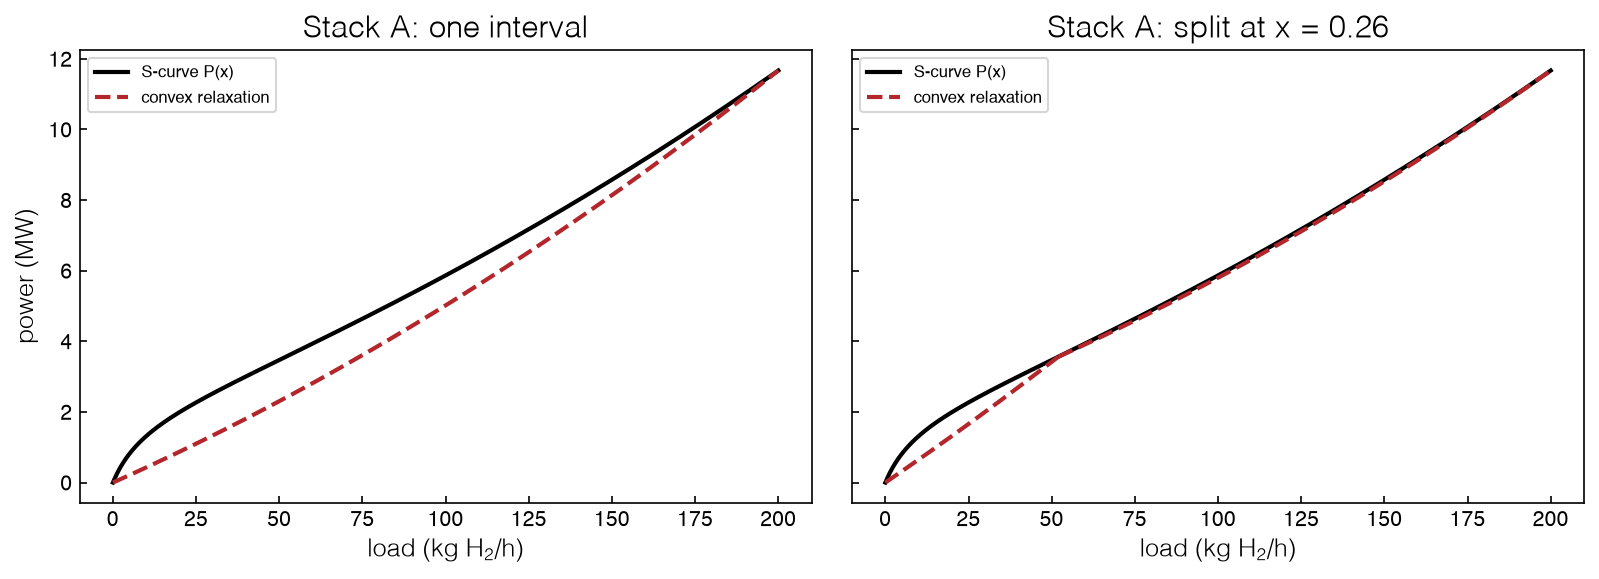

In [5]:
xs = np.linspace(0, 1, 1001)
print(f"stack A, max underestimation of the secant on [0, 1]: {bt.max_underestimation(a, 0, 1):.4f}")
print(f"after a split at the inflection x = 0.26: [0, 0.26] {bt.max_underestimation(a, 0, 0.26):.4f}, "
      f"[0.26, 1] {bt.max_underestimation(a, 0.26, 1):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, cuts, title in [(axes[0], [0, 1], 'one interval'), (axes[1], [0, 0.26, 1], 'split at x = 0.26')]:
    ax.plot(el.to_kg_h(xs), el.to_mw(bt.P(xs, a, r)), 'k', label='S-curve $P(x)$')
    for lo, hi in zip(cuts[:-1], cuts[1:]):
        t = np.linspace(lo, hi, 200)
        c0, c1 = bt.secant(a, lo, hi)
        ax.plot(el.to_kg_h(t), el.to_mw(t + c0 + c1 * t + r * t**2), '--', color='#B3262B')
    ax.plot([], [], '--', color='#B3262B', label='convex relaxation')
    ax.set_title(f'Stack A: {title}'); ax.set_xlabel('load (kg H$_2$/h)'); ax.legend(fontsize=8)
axes[0].set_ylabel('power (MW)')
plt.tight_layout()

On the whole range $[0, 1]$ the secant underestimates the concave term of stack A by up to 0.1834 per-unit. If we split the interval at the inflection point, $x = 0.26$, and draw a separate secant on each piece, the worst underestimation is reduced to 0.1074 on $[0, 0.26]$ and 0.0101 on $[0.26, 1]$. **Smaller intervals give tighter relaxations**, and this observation is the foundation of spatial branch-and-bound.

In thermodynamic terms, replacing a non-convex curve by its convex envelope is similar to the common-tangent construction for a non-convex free energy, which also replaces a curve by the lowest convex function beneath it. We will note the resemblance here but will not build on the analogy.

Other terms have dedicated estimators, and the development of tight estimators remains an active field of research. Exponential terms are common, for example in Arrhenius rate laws as well as many fitted surrogate models. On an interval the convex function $e^x$ can be used directly as the convex underestimator, but a linear relaxation is often needed. In this case any tangent line can be used, since a tangent will lie below a convex function. In the other direction, the secant lies above the function and is the tightest concave overestimator, which is what is needed for a maximization.

In [6]:
xl, xu = -2.0, 2.0
t = np.linspace(xl, xu, 40001)
fx = np.exp(t)
sec_e = np.exp(xl) + (np.exp(xu) - np.exp(xl)) / (xu - xl) * (t - xl)        # concave (linear) overestimator
tan0 = 1 + t                                                                 # tangent at x = 0
tans = np.max([np.exp(c) * (1 + t - c) for c in (-2, -1, 0, 1, 2)], axis=0)  # max of five tangents
print(f"secant: largest overestimate {np.max(sec_e - fx):.3f} at x = {t[np.argmax(sec_e - fx)]:.2f}")
print(f"one tangent at 0: largest underestimate {np.max(fx - tan0):.3f}; "
      f"five tangents: {np.max(fx - tans):.3f}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(t, fx, 'k', label='$e^x$')
ax.plot(t, sec_e, '--', color='#B3262B', label='secant (overestimator)')
ax.plot(t, tan0, ':', color='#003057', lw=2, label='tangent at 0 (underestimator)')
ax.plot(t, tans, '-.', color='#4B8B9B', label='max of five tangents')
ax.set_xlabel('$x$ (dimensionless)'); ax.set_ylabel('$f(x)$ (dimensionless)')
ax.set_title('Linear bounds on $e^x$, $-2 \\le x \\le 2$'); ax.legend(fontsize=8);

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


secant: largest overestimate 3.028 at x = 0.60
one tangent at 0: largest underestimate 4.389; five tangents: 0.564
Error in callback <function _draw_all_if_interactive at 0x11220bce0> (for post_execute), with arguments args (),kwargs {}:


ValueError: 
-2 \le x \le 2
   ^
ParseFatalException: Unknown symbol: \le, found '\'  (at char 3), (line:1, col:4)

ValueError: 
-2 \le x \le 2
   ^
ParseFatalException: Unknown symbol: \le, found '\'  (at char 3), (line:1, col:4)

<Figure size 900x600 with 1 Axes>

On $[-2, 2]$ the secant overestimates $e^x$ by up to 3.03, and a single tangent at zero underestimates it by up to 4.39 at the right end. If we take the maximum of five tangents, which gives a piecewise-linear convex underestimator, the worst underestimate is reduced to 0.56. Both bounds become tighter on smaller intervals, so both are useful inside branch-and-bound.

The bilinear product of a flow and a concentration is the term that appears most often in chemical engineering models, and has a classical construction of its own.

:::{admonition} Aside: McCormick envelopes for a bilinear term
:class: note

A bilinear term $w = xy$ is neither convex nor concave. Given bounds $x^L \le x \le x^U$ and $y^L \le y \le y^U$, the products $(x - x^L)(y - y^L) \ge 0$, $(x^U - x)(y^U - y) \ge 0$, $(x^U - x)(y - y^L) \ge 0$ and $(x - x^L)(y^U - y) \ge 0$ all hold. Expanding them and replacing $xy$ by $w$ gives four linear inequalities, the **McCormick envelopes** (McCormick, 1976):

$$
w \ge x^L y + x y^L - x^L y^L, \quad w \ge x^U y + x y^U - x^U y^U, \quad w \le x^U y + x y^L - x^U y^L, \quad w \le x^L y + x y^U - x^L y^U .
$$

The first two are convex underestimators and the last two concave overestimators; together they are the convex and concave envelopes of $xy$ on the box. As with the secant, they become exact as the box shrinks. The figure shows them along the diagonal $x = y = t$ of the unit box, where $w = t^2$.
:::

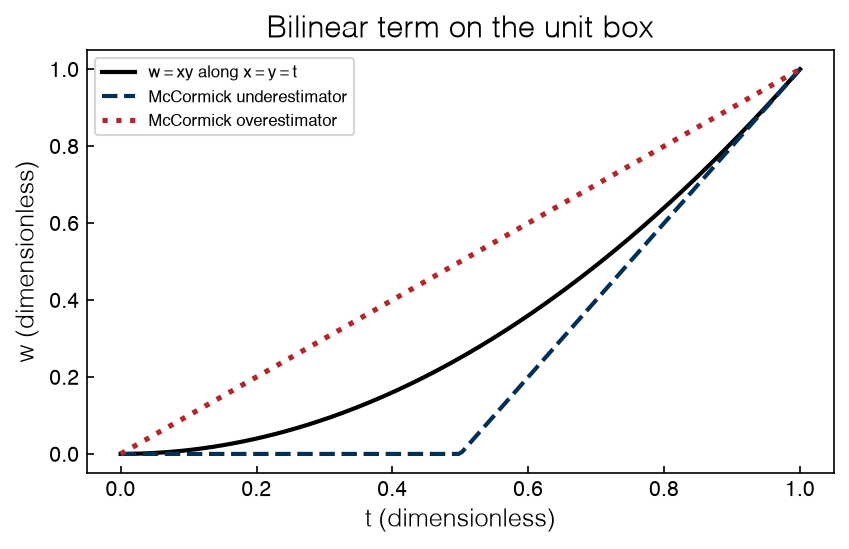

In [7]:
t = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(t, t * t, 'k', label='$w = xy$ along $x = y = t$')
ax.plot(t, np.maximum(0 * t, 2 * t - 1), '--', color='#003057', label='McCormick underestimator')
ax.plot(t, t, ':', color='#B3262B', lw=2.5, label='McCormick overestimator')
ax.set_xlabel('$t$ (dimensionless)'); ax.set_ylabel('$w$ (dimensionless)')
ax.set_title('Bilinear term on the unit box'); ax.legend(fontsize=8);

:::{exercise}
:label: ex-t26-exp

Build a convex underestimator and a concave overestimator for $-e^x$ on $[-2, 2]$, as a maximization would need for a term $-e^x$ in its objective. Then split the interval at $x = 0$ and recompute the worst gap of the secant on each half. By what factor does one split tighten it?
:::

:::{exercise}
:label: ex-t26-envelope

Compute the maximum underestimation of the secant for stacks B and C on $[0, 1]$, and after a split at $x = 0.26$. Which stack's relaxation is loosest, and why (look at $a_i$)? Then find, by a one-dimensional search, the split point that minimizes the larger of the two children's underestimations for stack A.
:::

## Spatial branch-and-bound

Why should we expect branching on continuous variables to give a convergent algorithm? A relaxation that is built from the bounds of the variables gets tighter as the bounds close in on each other. In a smaller box the curve is approximated more closely by the secant, and the true function is approximated more closely by the relaxation. In practice the important thing is whether the relaxations are sufficiently tight for pruning. When the relaxations are too loose, very few boxes can be removed by pruning, and the tree will grow until it has enumerated a fine grid.

We now have all of the pieces for a global algorithm on the two-stack problem. Each node is a box of loads, and at each node we form the relaxation by replacing the concave term of each stack with its secant over the interval of that stack. This gives a convex problem, and hence a valid lower bound. Any feasible point, polished by a local solve of the true problem, gives an upper bound. If the bound of a node is no better than the incumbent, we can prune the node. Otherwise we need to branch, and in this case the branch is **spatial**: we split the load interval of one stack in two at the solution of the relaxation, which gives each child its own tighter secant.

The node relaxations have a structure that is worth using. With the secants in place, the cost of each stack is $k_i x_i + c_{0,i} + r_i x_i^2$, which is separable across stacks, and the only coupling is through the demand. This means that the Lagrangian with a multiplier $\lambda$ on the demand is also separable, and the best response of each stack is $x_i(\lambda) = \text{clip}\big((\lambda - k_i)/2r_i,\ l_i,\ u_i\big)$. A bisection on $\lambda$ until $\sum_i x_i(\lambda) = D$ then finds the KKT point of the relaxation. Since the relaxation is convex, its value is certified by strong duality (Topic 2.3), so the bound is a proven floor and not just a number returned by a solver.

In economic terms, $\lambda$ is the hydrogen price of Topics 2.2 and 2.3, which now appears inside the tree: the bound at each node is the optimistic appraisal of that box by the broker, priced at the marginal cost of one more unit of demand.

spatial B&B: power 1.58921 at x = [0.9 0. ], final gap 0.0e+00
nodes processed 12, spatial branches 9, nodes created 19
brute force: 1.58921 at {1: 0.000, 2: 0.900}
root bound by price dual 1.359643 (lambda = 1.7357); SLSQP 1.359643; difference 2.2e-16


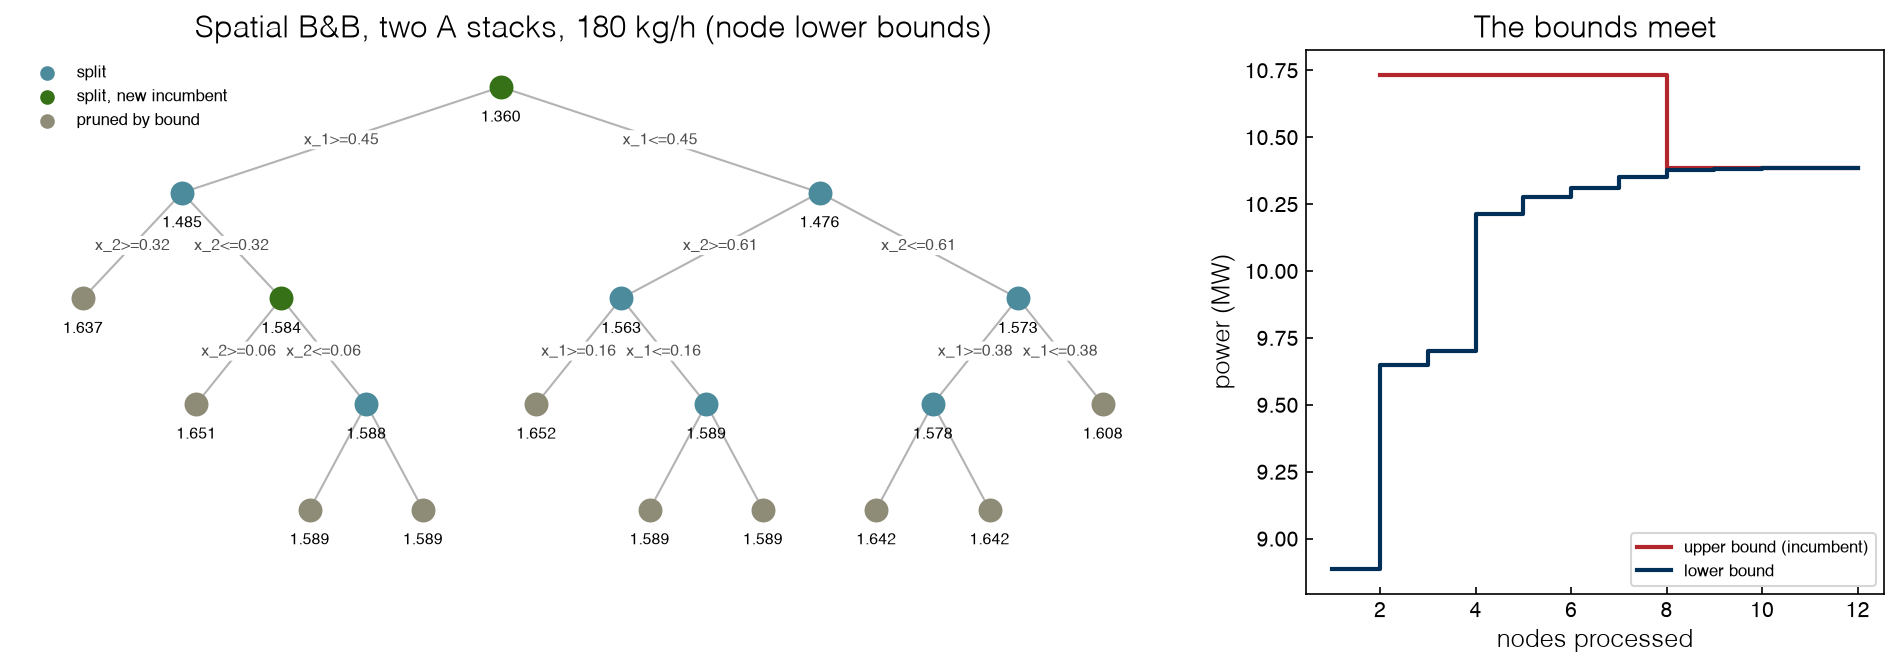

In [8]:
cells2 = [bt.CELLS['A'], bt.CELLS['A']]
sp = bt.minlp_bb(cells2, D, binaries=False, names=['1', '2'])
print(f"spatial B&B: power {sp['ub']:.5f} at x = {np.round(sp['x'], 4)}, final gap {sp['ub'] - sp['lb']:.1e}")
print(f"nodes processed {sp['stats']['nodes']}, spatial branches {sp['stats']['spatial_branches']}, "
      f"nodes created {len(sp['log'])}")
bf = bt.brute_force(cells2, D, binaries=False, names=['1', '2'])
print(f"brute force: {bf[0][0]:.5f} at {{{', '.join(f'{k}: {v:.3f}' for k, v in bf[0][2].items())}}}")

# cross-check the root bound: the price dual against a general-purpose solve of the same convex relaxation
root = bt.Node([0, 0], [1, 1], [1, 1], 0, None, 'root')
xd, _, val_dual, lam, sec = bt.relaxation_dual(root, cells2, D, binaries=False)
relax = lambda v: sum(v[i] + sec[i][0] + sec[i][1] * v[i] + r * v[i]**2 for i in range(2))
val_slsqp = minimize(relax, [0.3, 0.6], method='SLSQP', bounds=[(0, 1)] * 2, constraints=demand,
                     options={'ftol': 1e-14}).fun
print(f"root bound by price dual {val_dual:.6f} (lambda = {lam:.4f}); SLSQP {val_slsqp:.6f}; "
      f"difference {abs(val_dual - val_slsqp):.1e}")

def sp_label(rec):
    return "—" if rec['bound'] is None else f"{rec['bound']:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [2, 1]})
bt.draw_tree(sp['log'], axes[0], label=sp_label, edge_label=lambda rec: rec['edge'] if rec['depth'] <= 3 else '')
axes[0].set_title('Spatial B&B, two A stacks, 180 kg/h (node lower bounds)')
for s, lab in [('spatial', 'split'), ('incumbent', 'split, new incumbent'), ('bound', 'pruned by bound')]:
    axes[0].scatter([], [], color=bt.STATUS_COLOR[s], label=lab)
axes[0].legend(loc='upper left', fontsize=8, frameon=False)
h = np.array(sp['history'])
axes[1].step(h[:, 0], el.to_mw(h[:, 2]), where='post', color='#B3262B', label='upper bound (incumbent)')
axes[1].step(h[:, 0], el.to_mw(h[:, 1]), where='post', color='#003057', label='lower bound')
axes[1].set_xlabel('nodes processed'); axes[1].set_ylabel('power (MW)')
axes[1].set_title('The bounds meet'); axes[1].legend(fontsize=8)
plt.tight_layout()

The tree processes 12 nodes (19 created) and makes 9 spatial branches, and closes the gap at 1.58921 with one stack carrying all 180 kg/h, which matches the brute-force result. The root bound of 1.3596 is loose because the secants on $[0, 1]$ are loose, and each split makes them tighter until every open box is pruned. The price-dual bound at the root agrees with a general-purpose solve to within solver precision.

Stated precisely, **branching trades one non-convex problem for a tree of convex relaxations; the bound-pair certifies the global optimum; the price is a combinatorial search, the same price integers impose.** Note that no integer variables were added to the problem, and nothing became convex as a whole. Unlike a branch on a binary, a spatial branch can always be repeated on a smaller interval, so spatial branch-and-bound can only terminate within a tolerance (here $10^{-4}$), not at the exact optimum.

:::{exercise}
:label: ex-t26-spatial

Run `bt.minlp_bb` on the two-stack problem at $D = 0.8$ and $D = 1.2$. How many nodes and spatial branches does each need, and which configuration is optimal? Then loosen `tol` to $10^{-2}$ at $D = 0.9$: how many nodes are saved?
:::

## The full MINLP

Now we can combine both kinds of branch in one tree. Each of the three stacks (A, B and C) has an on/off binary $y_i$, a fixed on-cost $F_{\text{on}} = 0.12$ (0.78 MW of standby power plus amortized start-up per running stack, as in Topic 2.4), a minimum load $x_{\min} = 0.1$, and the S-curve, and the stacks need to meet $D = 1.2$ (240 kg/h):

$$
\min_{x,\,y} \ \sum_i \left[ F_{\text{on}} y_i + P_i(x_i) \right] \quad \text{s.t.} \quad \sum_i x_i = D, \quad x_{\min} y_i \le x_i \le y_i, \quad y_i \in \{0, 1\} .
$$

At each node the binaries are relaxed to $[0, 1]$, as in Topic 2.5, and the concave terms are relaxed to their secants (as in the previous section). The first choice is to branch on a fractional binary; if all of the binaries are integer, the tree splits the interval of the stack with the loosest secant.

optimum A+C, loads [0.703 0.    0.497], cost 2.32181 per-unit = 15.17 MW, gap 0.0e+00
20 nodes processed: 6 binary branches, 13 spatial branches, 3 pruned as infeasible; nodes created 39
brute force, best configurations:
  A+C   2.32181 (15.17 MW)  loads A 0.703, C 0.497
  B+C   2.33012 (15.23 MW)  loads B 0.812, C 0.388
  A+B   2.38236 (15.57 MW)  loads A 0.483, B 0.717
local minima of the split: {'A+C': 1, 'B+C': 1, 'A+B': 1}
root secant bound with y fixed to A+C: 2.2757 vs true 2.3218 (2.0% loose)


 demand (kg/h) | B&B: plan   cost     nodes | brute force
     120       | C     1.15662    12  | C     1.15662
     180       | B     1.68245    11  | B     1.68245
     240       | A+C   2.32181    20  | A+C   2.32181
     300       | B+C   2.82777    17  | B+C   2.82777
     360       | A+B   3.37331     9  | A+B   3.37331


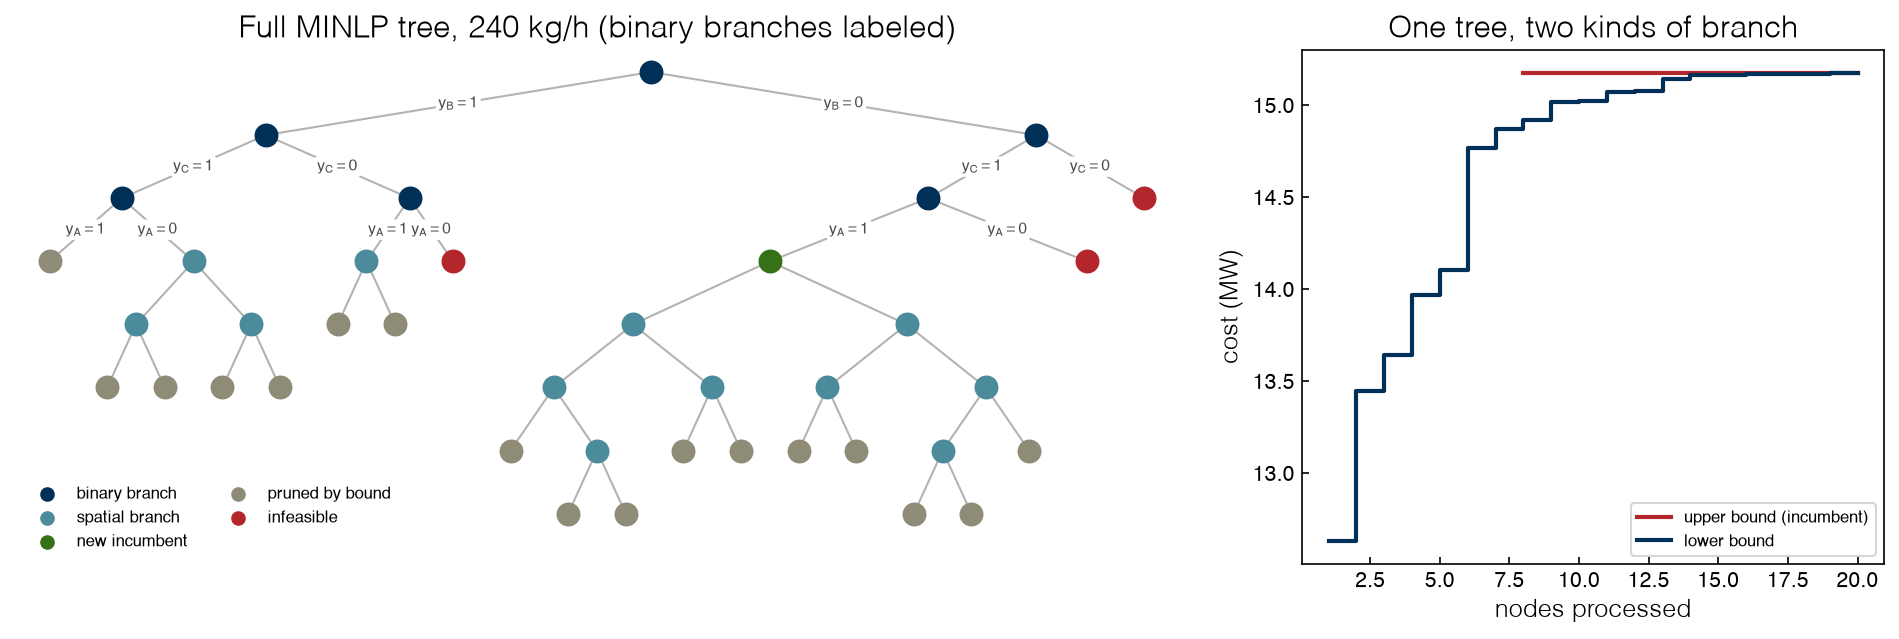

In [9]:
cells = [bt.CELLS[c] for c in el.NAMES]
full = bt.minlp_bb(cells, 1.2)
s = full['stats']
print(f"optimum {bt.minlp_config(full)}, loads {np.round(full['x'], 3)}, cost {full['ub']:.5f} per-unit "
      f"= {el.to_mw(full['ub']):.2f} MW, gap {full['ub'] - full['lb']:.1e}")
print(f"{s['nodes']} nodes processed: {s['binary_branches']} binary branches, {s['spatial_branches']} spatial "
      f"branches, {s['pruned_infeasible']} pruned as infeasible; nodes created {len(full['log'])}")
bfull = bt.brute_force(cells, 1.2)
print("brute force, best configurations:")
for v, cfg, xd in bfull[:3]:
    print(f"  {cfg:5s} {v:.5f} ({el.to_mw(v):.2f} MW)  loads " + ", ".join(f"{k} {t:.3f}" for k, t in xd.items()))

# with the binaries fixed to each two-stack configuration: how many local minima has the split?
def n_local_minima(i, j, Dd=1.2):
    xs = np.linspace(max(bt.X_MIN, Dd - 1), min(1, Dd - bt.X_MIN), 4001)
    v = bt.P(xs, *cells[i]) + bt.P(Dd - xs, *cells[j])
    return sum(1 for k in range(len(xs)) if (k == 0 or v[k] <= v[k - 1]) and (k == len(xs) - 1 or v[k] <= v[k + 1]))
print("local minima of the split:", {el.NAMES[i] + '+' + el.NAMES[j]: n_local_minima(i, j)
                                     for i, j in [(0, 2), (1, 2), (0, 1)]})
fixed = bt.Node([0] * 3, [1] * 3, [1, 0, 1], 0, None, 'y fixed to A+C')
lb_fixed = bt.relaxation_dual(fixed, cells, 1.2, binaries=True)[2]
print(f"root secant bound with y fixed to A+C: {lb_fixed:.4f} vs true {full['ub']:.4f} "
      f"({100 * (full['ub'] - lb_fixed) / full['ub']:.1f}% loose)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [2, 1]})
bt.draw_tree(full['log'], axes[0], edge_label=lambda rec: rec['edge'] if rec['edge'].startswith('y') else '')
axes[0].set_title('Full MINLP tree, 240 kg/h (binary branches labeled)')
for st, lab in [('branch', 'binary branch'), ('spatial', 'spatial branch'), ('incumbent', 'new incumbent'),
                ('bound', 'pruned by bound'), ('infeasible', 'infeasible')]:
    axes[0].scatter([], [], color=bt.STATUS_COLOR[st], label=lab)
axes[0].legend(loc='lower left', fontsize=8, frameon=False, ncol=2)
h = np.array(full['history'])
axes[1].step(h[:, 0], el.to_mw(h[:, 2]), where='post', color='#B3262B', label='upper bound (incumbent)')
axes[1].step(h[:, 0], el.to_mw(h[:, 1]), where='post', color='#003057', label='lower bound')
axes[1].set_xlabel('nodes processed'); axes[1].set_ylabel('cost (MW)')
axes[1].set_title('One tree, two kinds of branch'); axes[1].legend(fontsize=8)
plt.tight_layout()

print(" demand (kg/h) | B&B: plan   cost     nodes | brute force")
for Dd in (0.6, 0.9, 1.2, 1.5, 1.8):
    rb, bb = bt.minlp_bb(cells, Dd), bt.brute_force(cells, Dd)[0]
    print(f"   {el.to_kg_h(Dd):5.0f}       | {bt.minlp_config(rb):5s} {rb['ub']:.5f}   {rb['stats']['nodes']:3d}  | "
          f"{bb[1]:5s} {bb[0]:.5f}")

A+C is certified as optimal by the tree, with A at 0.703 and C at 0.497, at 2.32181 per-unit (15.17 MW). The runner-up is B+C at 2.33012, which is only 0.4% worse, and this is why it is worth having a proof. In total the tree processes 20 nodes (39 created), with 6 binary branches, 13 spatial branches and 3 prunes by infeasibility, and closes the gap to zero.

We can use the two lines about local minima and the root bound to understand why so many of these nodes are spatial. At this demand the non-convexity that we saw earlier is removed by the binaries: once each two-stack configuration is fixed, there is a single local minimum for the split, so a local solver would find the best split of A+C from any starting point. However, the secant bound with the binaries fixed to A+C is 2.2757, which is 2.0% below the true cost, and 13 spatial branches are needed to close that gap. **You branch to prove optimality, not only to find it.** A+C was found by the tree at the first feasible node with all three binaries fixed, and almost all of the remaining work was spent certifying this solution.

The best configuration changes with demand, from C alone at 120 kg/h and B alone at 180 to A+C at 240, B+C at 300 and A+B at 360 kg/h, and at every demand the tree matches the brute-force result.

:::{exercise}
:label: ex-t26-minlp

Raise the fixed on-cost $F_{\text{on}}$ from 0.12 to 0.3 (set `bt.F_ON = 0.3` and rerun the demand sweep; reset it afterwards). Which configurations change, and why? How does the number of nodes at 240 kg/h change?
:::

## Why the bound must be valid

What happens if we skip the convex relaxation, and instead simply solve the true non-convex node problem at each node with a local solver, taking the answer as the \"bound\" of the node? The tree looks the same and runs the same, and in the next cell we run it at every demand.

In [10]:
print(" demand (kg/h) | local-'bound' tree: plan  cost   reported gap | true optimum")
for Dd in (0.6, 0.9, 1.2, 1.5, 1.8):
    loc, bb = bt.minlp_bb(cells, Dd, bounds='local'), bt.brute_force(cells, Dd)[0]
    flag = "" if abs(loc['ub'] - bb[0]) < 2e-4 else "   <-- wrong"
    print(f"   {el.to_kg_h(Dd):5.0f}       | {bt.minlp_config(loc):5s} {loc['ub']:.5f}   {max(0, loc['ub'] - loc['lb']):.1e}"
          f"     | {bb[1]:5s} {bb[0]:.5f}{flag}")

 demand (kg/h) | local-'bound' tree: plan  cost   reported gap | true optimum
     120       | C     1.15662   0.0e+00     | C     1.15662
     180       | B     1.68245   0.0e+00     | B     1.68245
     240       | A+C   2.32181   0.0e+00     | A+C   2.32181
     300       | B+C   2.82777   0.0e+00     | B+C   2.82777
     360       | B+C   3.40719   0.0e+00     | A+B   3.37331   <-- wrong


At four demands the local-bound tree happens to give the right answer. However, at 360 kg/h ($D = 1.8$) it returns B+C at 3.40719 and reports a gap of zero, while the true optimum is A+B at 3.37331. A local solve of a non-convex problem can stop above the true minimum of the node, so its value is not a floor, and pruning against this value can discard the node that holds the optimum. The reported gap is zero because the algorithm compared two numbers, and one of these numbers was not a bound.

Production solvers show the same split. **Couenne** is a global solver that uses spatial branch-and-bound with convex relaxations, as we did. In its default mode **Bonmin** runs NLP-based branch-and-bound with Ipopt (a local solver) at each node, which is exact on convex MINLPs and a heuristic on non-convex ones.

In [11]:
def minlp_model(Dd, scale=1.0):
    m = pyo.ConcreteModel()
    m.I = pyo.Set(initialize=el.NAMES)
    m.x = pyo.Var(m.I, bounds=(0, 1))
    m.y = pyo.Var(m.I, within=pyo.Binary)
    m.demand = pyo.Constraint(expr=sum(m.x[i] for i in m.I) == Dd)
    m.cap = pyo.Constraint(m.I, rule=lambda m, i: m.x[i] <= m.y[i])
    m.min_load = pyo.Constraint(m.I, rule=lambda m, i: m.x[i] >= bt.X_MIN * m.y[i])
    m.cost = pyo.Objective(expr=scale * sum(bt.F_ON * m.y[i] + m.x[i] + el.A_PARASITIC[i] * m.x[i] / (m.x[i] + bt.EPS)
                                            + el.R_OHMIC[i] * m.x[i]**2 for i in m.I))
    return m

paths = {name: bt.find_solver(name) for name in ('couenne', 'bonmin')}
def run(name, Dd, scale=1.0):
    m = minlp_model(Dd, scale)
    pyo.SolverFactory(name, executable=paths[name]).solve(m)
    return "+".join(i for i in el.NAMES if pyo.value(m.y[i]) > 0.5), pyo.value(m.cost) / scale

if all(paths.values()):
    for scale, unit in [(1.0, 'objective in per-unit'), (el.MW_PER_UNIT, 'objective in MW')]:
        print(f"{unit}:\n demand (kg/h) | Couenne (global)  | Bonmin (local)    | true optimum")
        for Dd in (0.6, 0.9, 1.2, 1.5, 1.8):
            (cc, cv), (bc, bv), bb = run('couenne', Dd, scale), run('bonmin', Dd, scale), bt.brute_force(cells, Dd)[0]
            mark = lambda v: "" if abs(v - bb[0]) < 2e-4 else " wrong"
            print(f"   {el.to_kg_h(Dd):5.0f}       | {cc:5s} {cv:.5f}{mark(cv):6s}| {bc:5s} {bv:.5f}{mark(bv):6s}| {bb[1]:5s} {bb[0]:.5f}")
else:
    print("Couenne and/or Bonmin not found:", paths, "- see the brute-force column of the previous table.")

objective in per-unit:
 demand (kg/h) | Couenne (global)  | Bonmin (local)    | true optimum


     120       | C     1.15662      | A     1.17692 wrong| C     1.15662


     180       | B     1.68245      | B     1.68245      | B     1.68245


     240       | A+C   2.32181      | A+B   2.38236 wrong| A+C   2.32181


     300       | B+C   2.82777      | A+B   2.85928 wrong| B+C   2.82777


     360       | A+B   3.37331      | A+B   3.37331      | A+B   3.37331
objective in MW:
 demand (kg/h) | Couenne (global)  | Bonmin (local)    | true optimum


     120       | C     1.15662      | C     1.15662      | C     1.15662


     180       | B     1.68245      | B     1.68245      | B     1.68245


     240       | A+C   2.32181      | A+B   2.38236 wrong| A+C   2.32181


     300       | B+C   2.82777      | A+B   2.85928 wrong| B+C   2.82777


     360       | A+B   3.37331      | B+C   3.40719 wrong| A+B   3.37331


With the objective in per-unit, Couenne certifies the true optimum at all five demands. Bonmin reports \"optimal\" at all five demands but is wrong in three cases: at 120 kg/h it runs A instead of C, and at 240 and 300 kg/h it runs A+B. It happens to be right at 360 kg/h, which is the demand where our local-bound tree gave the wrong answer. The failures are different, but the lesson is the same: **a local MINLP solver on a non-convex model is a heuristic that reports success.**

In the second table the objective is multiplied by 6.535 to express it in MW, and nothing else is changed. The answers from Couenne are the same as before. Bonmin is still wrong at three of the five demands, but now at 240, 300 and 360 kg/h, and at 360 kg/h it returns B+C at 3.40719, which is the same wrong answer as our local-bound tree. Solvers use absolute tolerances, so rescaling the objective changes the path taken by a local search, and on a non-convex model a different path can end in a different well. This is one reason that the book computes in per-unit and converts only for display, so that every number we quote has one value.

This explains the solver landscape that we described in Topic 2.4. Bonmin and DICOPT are only exact on convex MINLPs, and if we want a certificate on a non-convex MINLP we need the valid bounds that are provided by BARON, ANTIGONE, Couenne, SCIP, or the non-convex mode of Gurobi. **The moment you trust a bound from a non-convex problem, you are doing global optimization, whether you meant to or not.**

:::{exercise}
:label: ex-t26-valid

Run the local-bound tree and Bonmin on a fine demand sweep, $D = 0.5$ to $2.0$ in steps of 0.05, and mark the demands where each is wrong. Do the two fail at the same demands? Then scale the objective by 100 instead of 6.535.
:::

## Summary

- Local minima can be distinct operating configurations: for two A stacks at 180 kg/h, one stack (1.58921, 10.39 MW) beats the equal split (1.6425, 10.73 MW), where a local solver stops and reports success.
- Multistart finds good solutions but proves nothing. A certificate needs a lower bound valid everywhere.
- The fixed charge of Topic 2.4 is the sharp-switch limit $\epsilon \to 0$ of the S-curve, with the losses linearized: a binary represents an infinitely sharp concave cost exactly.
- Valid bounds come from convex underestimators: secants of concave terms (0.1834 on $[0, 1]$, 0.1074 and 0.0101 after one split), tangents and secants of $e^x$, McCormick envelopes of $xy$.
- Spatial branch-and-bound splits continuous intervals to tighten the relaxations. On two stacks it certifies the optimum in 12 nodes processed (19 created), with every node's bound certified by its price dual.
- The full MINLP at 240 kg/h is solved by one tree with binary and spatial branches: A+C at 2.32181 (15.17 MW), against B+C at 2.33012, in 20 nodes processed (39 created). You branch to prove optimality, not only to find it.
- With local solves as "bounds" the tree is wrong with a zero gap; Bonmin is wrong at three of five demands (which three depends on the objective's units); Couenne is right at all five.

## Additional Reading

- McCormick, G. P. Computability of global solutions to factorable nonconvex programs: Part I — Convex underestimating problems. *Mathematical Programming* 10, 147–175 (1976).
- Floudas, C. A. *Deterministic Global Optimization: Theory, Methods and Applications*. Kluwer, 2000.
- Tawarmalani, M., and Sahinidis, N. V. *Convexification and Global Optimization in Continuous and Mixed-Integer Nonlinear Programming*. Kluwer, 2002.
- Belotti, P., Lee, J., Liberti, L., Margot, F., and Wächter, A. Branching and bounds tightening techniques for non-convex MINLP. *Optimization Methods and Software* 24, 597–634 (2009). Couenne's algorithms.
- Bonami, P., Biegler, L. T., Conn, A. R., Cornuéjols, G., Grossmann, I. E., Laird, C. D., Lee, J., Lodi, A., Margot, F., Sawaya, N., and Wächter, A. An algorithmic framework for convex mixed integer nonlinear programs. *Discrete Optimization* 5, 186–204 (2008). Bonmin's algorithms.
- Gounaris, C. E., and Floudas, C. A. Tight convex underestimators for $\mathcal{C}^2$-continuous problems, I: univariate functions, and II: multivariate functions. *Journal of Global Optimization* 42 (2008).
- Biegler, L. T. *Nonlinear Programming: Concepts, Algorithms, and Applications to Chemical Processes*. SIAM, 2010.